In [1]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
import warnings
from sklearn import set_config

set_config(display='text')
warnings.filterwarnings('ignore')

# DecisionTree Classifier 생성
dt_clf = DecisionTreeClassifier(random_state=156)

# 붓꽃 데이터를 로딩하고, 학습과 테스트 데이터 세트로 분리
iris_data = load_iris()
X_train, X_test, y_train, y_test = train_test_split(iris_data.data, iris_data.target, test_size=0.2, random_state=11)

# DecisionTreeClassifier 학습
dt_clf.fit(X_train, y_train)

from sklearn.tree import export_graphviz

# export_graphviz()의 호출 결과로 out_file로 지정된 tree.dot 파일을 생성함
export_graphviz(dt_clf, out_file="tree.dot", class_names=iris_data.target_names,\
                feature_names=iris_data.feature_names, impurity=True, filled=True)

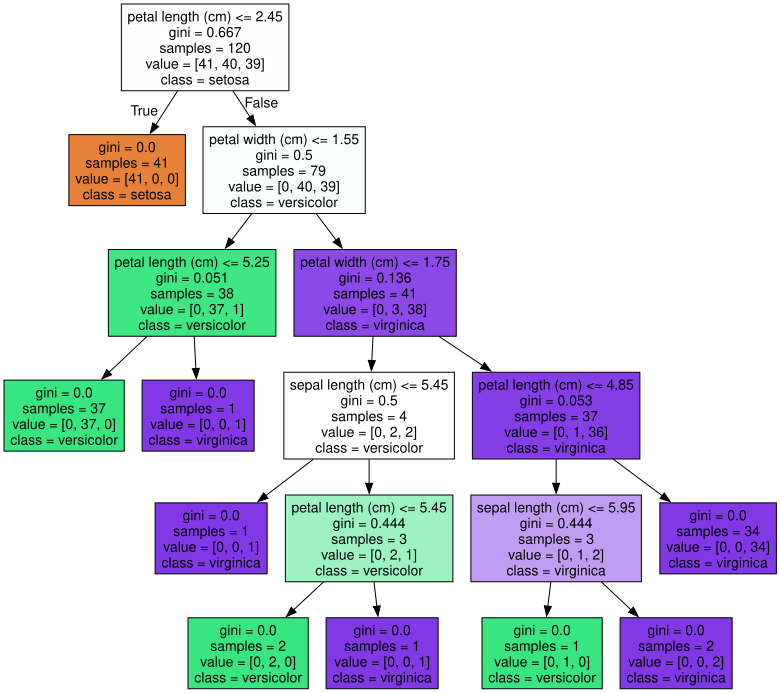

In [2]:
import graphviz
# 위에서 생성된 tree.dot 파일을 Graphviz가 읽어서 주피터 노트북상에서 시각화
with open("tree.dot") as f:
    dot_graph = f.read()
graphviz.Source(dot_graph)

Feature importances:
[0.025 0.    0.555 0.42 ]
sepal length (cm): 0.025
sepal width (cm): 0.000
petal length (cm): 0.555
petal width (cm): 0.420


<Axes: >

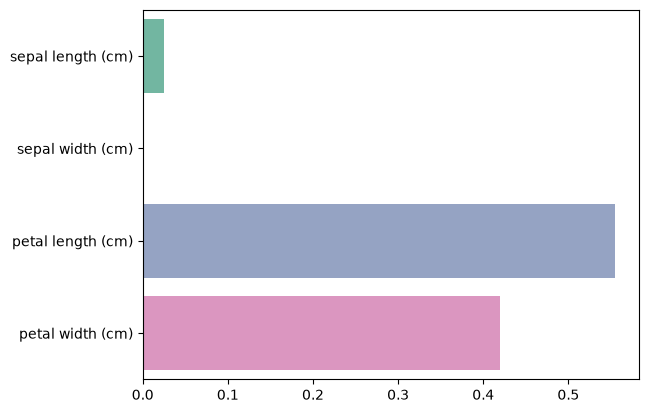

In [5]:
import seaborn as sns
import numpy as np
%matplotlib inline

# feature importance 추출
#print("Feature importances:\n{0}".format(np.round(dt_clf.feature_importances_, 3)))
print(f"Feature importances:\n{np.round(dt_clf.feature_importances_, 3)}")

# feature 별 importance 매핑
for name, value in zip(iris_data.feature_names, dt_clf.feature_importances_):
    #print('{0}: {1:.3f}'.format(name, value))
    print(f'{name}: {value:.3f}')

# feature importance를 column 별로 시각화 하기
sns.barplot(
    x=dt_clf.feature_importances_,
    y=iris_data.feature_names,
    hue=iris_data.feature_names,
    palette='Set2',
    legend=False
)

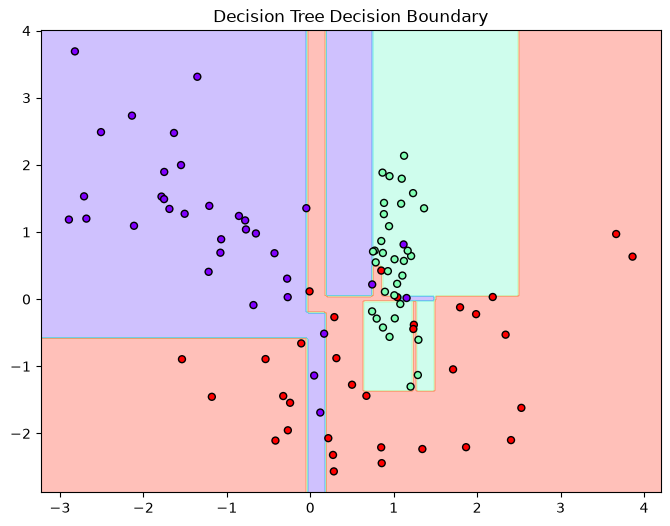

In [11]:
from sklearn.datasets import make_classification
from sklearn.tree import DecisionTreeClassifier
import matplotlib.pyplot as plt
import numpy as np

%matplotlib inline

# 결정 경계 시각화 함수
def visualize_boundary(model, X, y):
    fig, ax = plt.subplots(figsize=(8, 6))

    # 학습 데이터를 점으로 표시
    ax.scatter(
        X[:, 0], X[:, 1],
        c=y,
        s=25,
        cmap='rainbow',
        edgecolor='k',
        zorder=3
    )

    ax.axis('tight')

    # 그래프의 x, y 범위 가져오기
    xlim_start, xlim_end = ax.get_xlim()
    ylim_start, ylim_end = ax.get_ylim()

    # 그래프 전체 영역에 격자 좌표 생성
    xx, yy = np.meshgrid(
        np.linspace(xlim_start, xlim_end, 200),
        np.linspace(ylim_start, ylim_end, 200)
    )

    # 각 좌표에 대해 결정 트리 예측
    Z = model.predict(
        np.c_[xx.ravel(), yy.ravel()]
    ).reshape(xx.shape)

    # 예측 결과에 따라 결정 경계 색칠
    ax.contourf(
        xx, yy, Z,
        alpha=0.3,
        cmap='rainbow'
    )

    plt.title("Decision Tree Decision Boundary")
    plt.show()


# 2차원 시각화를 위해 피처는 2개, 클래스는 3개 유형의 분류 샘플 데이터 생성
X_features, y_labels = make_classification(
    n_features=2,
    n_redundant=0,
    n_informative=2,
    n_classes=3,
    n_clusters_per_class=1,
    random_state=0
)

# 결정 트리 생성 및 학습
dt_clf = DecisionTreeClassifier(random_state=156)
dt_clf.fit(X_features, y_labels)

# 결정 경계 시각화
visualize_boundary(dt_clf, X_features, y_labels)